# Plots for the task

# Libraries

In [1]:
import os

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from matplotlib.patches import Patch
from scipy.stats import ttest_ind

## Paths

In [2]:
ROOT_PATH = os.path.join(os.getcwd(), "query_results")

PATH2QUERY1 = os.path.join(ROOT_PATH, "query1", "query1_result.csv")
PATH2QUERY2 = os.path.join(ROOT_PATH, "query2", "query2_result.csv")
PATH2QUERY2_EXTRA = os.path.join(ROOT_PATH, "query2", "daily_avg_per_region.csv")
PATH2QUERY3 = os.path.join(ROOT_PATH, "query3", "query3_result.csv")
PATH2QUERY4 = os.path.join(ROOT_PATH, "query4", "query4_result.csv")
PATH2_CASE_STUDIES_GU = os.path.join(ROOT_PATH, "case_study", "general_understanding.csv")
PATH2_CASE_STUDIES_INDS = os.path.join(ROOT_PATH, "case_study", "groupby_industries.csv")
PATH2_CASE_STUDIES_REG = os.path.join(ROOT_PATH, "case_study", "groupby_regions.csv")
PATH2_CASE_STUDIES_PRD = os.path.join(ROOT_PATH, "case_study", "groupby_product_categories.csv")
PATH2_CASE_STUDIES_YEARS = os.path.join(ROOT_PATH, "case_study", "groupby_years.csv")

PATH2PLOTS = os.path.join(ROOT_PATH, "plots")

ROOT_PATH2PLOTS = os.path.join(os.getcwd(), "plots")

PATH2PLOTS_QUERY1 = os.path.join(ROOT_PATH2PLOTS, "query1")
os.makedirs(PATH2PLOTS_QUERY1, exist_ok=True)

PATH2PLOTS_QUERY2 = os.path.join(ROOT_PATH2PLOTS, "query2")
os.makedirs(PATH2PLOTS_QUERY2, exist_ok=True)

PATH2PLOTS_QUERY3 = os.path.join(ROOT_PATH2PLOTS, "query3")
os.makedirs(PATH2PLOTS_QUERY3, exist_ok=True)

PATH2PLOTS_QUERY4 = os.path.join(ROOT_PATH2PLOTS, "query4")
os.makedirs(PATH2PLOTS_QUERY4, exist_ok=True)

PATH2PLOTS_CASE_STUDY = os.path.join(ROOT_PATH2PLOTS, "case_study")
os.makedirs(PATH2PLOS_CASE_STUDY, exist_ok=True)

NameError: name 'PATH2PLOS_CASE_STUDY' is not defined

In [ ]:
plt.rcParams["font.family"] = "Times New Roman"
plt.rcParams["font.size"] = 12

# Query 1: Ventas y beneficio por categoría en Adabs Entertainment

```
SELECT category AS "Categoría",
       ROUND(SUM(maintenance),2) AS "Mantenimiento",
       ROUND(SUM(product),2) AS "Producto",
       ROUND(SUM(parts),2) AS "Partes",
       ROUND(SUM(support),2) AS "Soporte",
       ROUND(SUM(total),2) AS "Total Ventas",
       ROUND(SUM(units_sold),2) AS "Unidades Vendidas",
       ROUND(SUM(profit),2) AS "Beneficio Total"
FROM sales
WHERE year = 2020 AND account = 'Adabs Entertainment'
GROUP BY category, year;
```

In [ ]:
df_query1 = pd.read_csv(PATH2QUERY1, sep=",", index_col="Categoría")
df_query1.head()

In [ ]:
x_labels = df_query1.index.tolist()

label_val_dict = {
    column: (df_query1.loc[:,column]/1000000).to_list() for column in df_query1.columns if column != "Unidades Vendidas"
}

label_val_dict["Unidades Vendidas"] = (df_query1.loc[:,"Unidades Vendidas"]/1000).to_list()

fig,ax1 = plt.subplots(figsize=(10,6))

ax1.grouped_bar(label_val_dict,
                tick_labels=x_labels,
                group_spacing=2,
                colors=sns.color_palette("cubehelix", n_colors=len(label_val_dict.keys())),
                edgecolor="black"
                )
ax1.set_ylabel("Millón ($)")
ax1.legend(loc="upper left",ncols=1)

ax2 = ax1.twinx()
ax2.set_ylim(0, 4)
ax2.set_ylabel("Miles de unidades", rotation=270, labelpad=20)

plt.title("Ventas por categoría Adabs Entertainment")
plt.savefig(os.path.join(PATH2PLOTS_QUERY1, "bar_plot.png"),
            format="png",
            bbox_inches="tight",
            dpi=300)
plt.show()

# Query 2: Rendimiento en países de APAC y EMEA

```
SELECT "Región",
       "País",
       ROUND(AVG("Ingreso Diario"),2) AS "Ingreso Diario Promedio",
       ROUND(AVG("Unidades Vendidas Diario"),2) AS "Unidades Vendidas Diario Promedio",
       ROUND(AVG("Beneficio Diario"),2)AS "Beneficio Diario Promerdio"
FROM (SELECT acc.region as "Región",
             acc.country as "País",
             ROUND(SUM(s.total),2) AS "Ingreso Diario",
             ROUND(SUM(s.units_sold),2) AS "Unidades Vendidas Diario",
             ROUND(SUM(s.profit),2) AS "Beneficio Diario"
      FROM  sales s
      JOIN accounts acc ON (s.account = acc.account)
      WHERE acc.region IN ('APAC', 'EMEA')
      GROUP BY acc.region, acc.country, s.date)
GROUP BY "Región", "País"
ORDER BY "Región", "Ingreso Diario Promedio"
;
```

In [ ]:
# Bar plots with region as label for color

df_query2 = pd.read_csv(PATH2QUERY2, sep=",", index_col="País")
df_query2.head()

In [ ]:
countries = df_query2.index.to_list()
regions = df_query2.loc[:,"Región"].to_list()
mean_incomes = df_query2.loc[:,"Ingreso Diario Promedio"].to_list()
mean_profits = df_query2.loc[:,"Beneficio Diario Promerdio"].to_list()
mean_units = df_query2.loc[:,"Unidades Vendidas Diario Promedio"].to_list()

fig, ax = plt.subplots(1,3, figsize=(18,6))

colors = {
    "APAC": "violet",
    "EMEA": "lightgreen"
}

for country,region,mean_income in zip(countries, regions, mean_incomes):
    ax[0].barh(
                y=country,
                width=mean_income,
                height=0.5,
                color=colors[region],
                edgecolor="black",
                orientation="horizontal",
            )

ax[0].set_xlabel("$")
ax[0].set_title("Ingreso promedio de países de regiones APAC y EMEA")
ax[0].legend(handles = [ Patch(color=color, label=region) for region, color in colors.items()],
             loc="center right")

for country,region,mean_profit in zip(countries, regions, mean_profits):
    ax[1].barh(
                y=country,
                width=mean_profit,
                height=0.5,
                color=colors[region],
                edgecolor="black",
                orientation="horizontal",
                )
    
ax[1].set_xlabel("$")
ax[1].set_title("Beneficio promedio de países de regiones APAC y EMEA")
ax[1].legend(handles = [ Patch(color=color, label=region) for region, color in colors.items()],
             loc="center right")


for country,region,mean_unit in zip(countries, regions, mean_units):
    ax[2].barh( y=country,
                width=mean_unit,
                height=0.5,
                color=colors[region],
                edgecolor="black",
                orientation="horizontal",
                )
    
ax[2].set_xlabel("Unidades vendidas")
ax[2].set_title("Unidades vendidas promedio de países de regiones APAC y EMEA")
ax[2].legend(handles = [ Patch(color=color, label=region) for region, color in colors.items()],
             loc="center right")


plt.tight_layout()
plt.savefig(os.path.join(PATH2PLOTS_QUERY2, "bar_plot.png"),
            format="png",
            bbox_inches="tight",
            dpi=300
            )
plt.show()

# 2. Extra: Ingreso promedio diario por región
```
WITH ingreso_por_fecha_pais AS (
     SELECT acc.region AS "Región",
            acc.country AS "País",
            s.date AS "Fecha",
            ROUND(SUM(s.total),2) AS "Ingreso Diario",
            ROUND(SUM(s.units_sold),2) AS "Unidades Vendidas Diario",
            ROUND(SUM(s.profit),2) AS "Beneficio Diario"
     FROM  sales s
     JOIN accounts acc ON (s.account = acc.account)
     WHERE acc.region IN ('APAC', 'EMEA')
     GROUP BY acc.region, acc.country, s.date
     ORDER BY "Región", "País", s.date
     ),
ingreso_promedio_diario_pais AS (
     SELECT "Región",
            "País",
            ROUND(AVG("Ingreso Diario"),2) AS "Ingreso Diario Promedio",
            ROUND(AVG("Unidades Vendidas Diario"),2) AS "Unidades Vendidas Diario Promedio",
            ROUND(AVG("Beneficio Diario"),2)AS "Beneficio Diario Promerdio"
     FROM ingreso_por_fecha_pais
     GROUP BY "Región", "País"
     ORDER BY "Región", "País"
)
SELECT "Región",
        ROUND(AVG("Ingreso Diario Promedio"), 2) AS "Ingreso promedio diario por región"
FROM ingreso_promedio_diario_pais,
GROUP BY "Región"
;
```

In [ ]:
df_query2_extra = pd.read_csv(PATH2QUERY2_EXTRA, sep=",", index_col="Región")
df_query2_extra.head()

In [ ]:
fig, ax = plt.subplots(figsize=(7, 6))

regions = df_query2_extra.index.to_list()
values = df_query2_extra.loc[:,"Ingreso promedio diario por región"].to_list()

ax.bar(x=regions,
       height=values,
       width=0.5,
       color=["violet", "lightgreen"],
       edgecolor="black"
       )

ax.legend(handles = [ Patch(color=color, label=region) for region, color in colors.items()],
             loc="upper right")

ax.set_title("Ingreso promedio diario de regiones APAC y EMEA")

plt.tight_layout()
plt.savefig(os.path.join(PATH2PLOTS_QUERY2, "avg_per_region.png"),
            format="png",
            bbox_inches="tight",
            dpi=300)
plt.show()

In [ ]:
income_apac = df_query2[df_query2["Región"]=="APAC"].loc[:,"Ingreso Diario Promedio"].to_numpy()
income_emea = df_query2[df_query2["Región"]=="EMEA"].loc[:,"Ingreso Diario Promedio"].to_numpy()

pvalue = round(ttest_ind(income_apac, income_emea).pvalue, 4)
if pvalue <= 0.05:
    print(f"{pvalue} <= 0.05. La diferencia es significativa.")
else:
    print(f"{pvalue} > 0.05. La diferencia no es significativa.")


# Query3: Beneficio estratégico por industria en cuentas con oportunidades cercanas al cierre en 2022

```
SELECT acc.industry AS "Industria",
       IFNULL(ROUND(SUM(s.profit), 2),0) AS "Beneficio Total",
       CASE
            WHEN "Beneficio Total" > 1000000 THEN 'Alto'
            ELSE 'Normal' END AS "Categoría Beneficio"
       FROM sales s
       RIGHT JOIN accounts acc ON (s.account = acc.account AND
                                   acc.account IN (SELECT fr.account
                                                   FROM accounts acc JOIN forecasts fr ON (acc.account = fr.account)
                                                   WHERE fr.prediction_category = 'Commit' AND fr.year='2022'
                                                   GROUP BY fr.account
                                                   HAVING SUM(fr.forecast) > 500000
                                                   )
                                    )
GROUP BY acc.industry
ORDER BY "Beneficio Total" DESC
;
```

In [ ]:
df_query3 = pd.read_csv(PATH2QUERY3, sep=",", index_col="Industria")
df_query3.head()

In [ ]:
industries = df_query3.index.to_list()
total_profits = (df_query3.loc[:,"Beneficio Total"]/1000000).to_list()
categories = df_query3.loc[:,"Categoría Beneficio"].to_list()

colors4categories ={
    "Normal": "lightblue",
    "Alto": "darkred"
}

fig,ax = plt.subplots(figsize=(10, 6))

for industry, total_profit, category in zip(industries, total_profits, categories):
    ax.barh(
        y=industry,
        width=total_profit,
        height=0.5,
        color=colors4categories[category],
        edgecolor="black",
    )

ax.set_xlabel("Millones de $")
ax.set_title("Beneficio histórico acumulado de industrias con proyectos en etapa commit en 2022")
ax.legend(handles=[ Patch(color=color, label=region) for region, color in colors4categories.items()],)

plt.tight_layout()
plt.savefig(os.path.join(PATH2PLOTS_QUERY3, "bar_plot.png"),
            format="png",
            bbox_inches="tight",
            dpi=300
            )
plt.show()

# Query 4: Análisis trimestral real vs target (2019–2021)

In [ ]:
df_query4 = pd.read_csv(PATH2QUERY4, sep=",", index_col=("Año", "Cuartil"))
df_query4.head()

In [ ]:
x_labels = [f"{year} Q{q}" for year,q in df_query4.index.to_list()]

fig, ax = plt.subplots(1,3,figsize=(18, 9))
years = ("2019", "2020", "2021")

for (fig_count, i), year in zip(enumerate(range(0,len(x_labels),4)), years):
    x_labels_per_year = x_labels[i:i+4]

    values_per_year = {
        column: (df_query4.loc[:,column]/1000000).to_list()[i:i+4]
        for column in df_query4.columns
    }

    ax[fig_count].grouped_bar(values_per_year,
                              tick_labels=x_labels_per_year,
                              orientation="horizontal",
                              colors=sns.color_palette("pastel",
                                                       n_colors=len(values_per_year.keys())),
                              edgecolor="black",
                              group_spacing=15
                              )
    ax[fig_count].axvline(0, color="black")
    ax[fig_count].legend()
    ax[fig_count].set_title(f"Target vs reality in {year}")
    ax[fig_count].set_xlabel("Millones de $")

plt.tight_layout()
plt.savefig(os.path.join(PATH2PLOTS_QUERY4, "bar_plot.png"),
            format="png",
            bbox_inches="tight",
            dpi=300)
plt.show()

# Case study: Patrón semanal de ventas
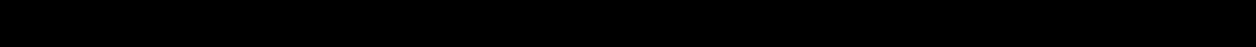
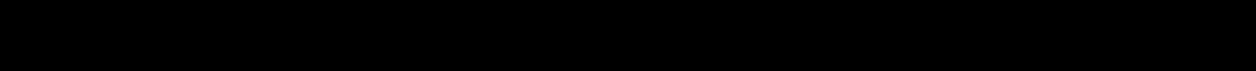

## Visión general
```
SELECT day_name AS "Día de la semana",
       COUNT(*) AS "Ventas totales por día de semana",
       ROUND(SUM(total), 2) AS "Ingreso por día de semana",
       ROUND(SUM(profit), 2) AS "Beneficio por día de semana",
       ROUND(SUM(units_sold), 2) AS "Unidades vendidas por día de semana",
       ROUND(AVG(total), 2) AS "Promedio de ingreso por día de semana",
       ROUND(AVG(profit),2) AS "Promedio de beneficio por día de semana",
       ROUND(AVG(units_sold), 2) AS "Promedio de unidades vendidos por día de semana"
FROM sales
GROUP BY day_name
ORDER BY CASE "Día de la semana" WHEN 'Monday' THEN 1
                                 WHEN 'Tuesday' THEN 2
                                 WHEN 'Wednesday' THEN 3
                                 WHEN 'Thursday' THEN 4
                                 WHEN 'Friday' THEN 5
                                 WHEN 'Saturday' THEN 6
                                 WHEN 'Sunday' THEN 7
        END
;
```

In [ ]:
df_cs_gu = pd.read_csv(PATH2_CASE_STUDIES_GU, sep=",", index_col = "Día de la semana")
df_cs_gu.head()

In [ ]:
x_labels = df_cs_gu.index.to_list()
x = np.arange(len(x_labels))

# Monetary values (ax1)
label_val_dict = {
    column: df_cs_gu[column].to_list()
    for column in df_cs_gu.columns
    if "Promedio" in column and "unidades" not in column
}

# Units sold (ax2)
units = (
    df_cs_gu["Promedio de unidades vendidos por día de semana"]
).to_numpy()

fig, ax1 = plt.subplots(figsize=(14, 6))

# Plot monetary values
n_bars = len(label_val_dict)
bar_width = 0.8 / n_bars

for i, (label, values) in enumerate(label_val_dict.items()):
    positions = x + (i - (n_bars - 1) / 2) * bar_width

    ax1.bar(
        positions,
        values,
        width=bar_width,
        label=label,
        color=sns.color_palette("cubehelix", n_colors=n_bars)[i],
        edgecolor="black"
    )

ax1.set_ylabel("$")
ax1.set_xticks(x)
ax1.set_xticklabels(x_labels)

# Secondary y-axis: units sold
ax2 = ax1.twinx()

ax2.plot(
    x,
    units,
    color="darkred",
    marker="o",
    linewidth=2.5,
    label="Promedio de unidades vendidos"
)

ax2.set_ylim(25, 36)
ax2.set_ylabel("Unidades", rotation=270, labelpad=20)

# Combined legend
handles1, labels1 = ax1.get_legend_handles_labels()
handles2, labels2 = ax2.get_legend_handles_labels()

ax1.legend(
    handles1 + handles2,
    labels1 + labels2,
    loc="upper right",
    ncols=1
)

plt.title("Visión genérica de ventas semanales")

plt.savefig(
    os.path.join(PATH2PLOTS_CASE_STUDY, "general_understanding.png"),
    format="png",
    bbox_inches="tight",
    dpi=300
)

plt.show()

## Visión por regiones
```
SELECT s.day_name AS "Día de la semana",
       acc.region AS "Región",
       COUNT(*) AS "Ventas totales por día de semana",
       ROUND(SUM(s.total), 2) AS "Ingreso por día de semana",
       ROUND(SUM(s.profit), 2) AS "Beneficio por día de semana",
       ROUND(SUM(s.units_sold), 2) AS "Unidades vendidas por día de semana",
       ROUND(AVG(s.total), 2) AS "Promedio de ingreso por día de semana",
       ROUND(AVG(s.profit),2) AS "Promedio de beneficio por día de semana",
       ROUND(AVG(s.units_sold), 2) AS "Promedio de unidades vendidas por día de semana"
FROM sales s JOIN accounts acc ON (s.account = acc.account)
GROUP BY s.day_name, acc.region
ORDER BY acc.region,
         CASE "Día de la semana" WHEN 'Monday' THEN 1
                                 WHEN 'Tuesday' THEN 2
                                 WHEN 'Wednesday' THEN 3
                                 WHEN 'Thursday' THEN 4
                                 WHEN 'Friday' THEN 5
                                 WHEN 'Saturday' THEN 6
                                 WHEN 'Sunday' THEN 7
         END
;
```

In [ ]:
df_regions = pd.read_csv(PATH2_CASE_STUDIES_REG, sep=",")
df_regions.head()

In [ ]:

days_order = [
    "Monday", "Tuesday", "Wednesday", "Thursday",
    "Friday", "Saturday", "Sunday"
]

regions = ["APAC", "EMEA", "LATAM", "NAM"]

# Average monetary values only
monetary_cols = [
    "Promedio de ingreso por día de semana",
    "Promedio de beneficio por día de semana"
]

units_col = "Promedio de unidades vendidos por día de semana"

colors = sns.color_palette("cubehelix", n_colors=len(monetary_cols))

fig, axes = plt.subplots(
    2, 2,
    figsize=(16, 10),
    sharex=True
)

for ax1, region in zip(axes.flat, regions):

    df_region = (
        df_regions[df_regions["Región"] == region]
        .set_index("Día de la semana")
        .reindex(days_order)
    )

    x = np.arange(len(days_order))

    # Left axis: average revenue and profit ($)
    for i, col in enumerate(monetary_cols):
        ax1.plot(
            x,
            df_region[col],
            marker="o",
            linewidth=2,
            color=colors[i],
            label=col
        )

    ax1.set_ylabel("$")
    ax1.set_title(region, fontsize=14, fontweight="bold")
    ax1.grid(axis="y", linestyle="--", alpha=0.3)

    # Right axis: average units sold (no transformation)
    ax2 = ax1.twinx()

    ax2.plot(
        x,
        df_region[units_col],
        color="darkred",
        marker="s",
        linestyle="--",
        linewidth=2.5,
        label="Promedio de unidades vendidos"
    )

    ax2.set_ylabel(
        "Promedio de unidades vendidas",
        rotation=270,
        labelpad=20
    )

    ax1.set_xticks(x)
    ax1.set_xticklabels(days_order, rotation=45, ha="right")
    ax1.tick_params(axis="x", labelbottom=True)

    # Combined legend
    handles1, labels1 = ax1.get_legend_handles_labels()
    handles2, labels2 = ax2.get_legend_handles_labels()

    ax1.legend(
        handles1 + handles2,
        labels1 + labels2,
        loc="center left",
        fontsize=8
    )

fig.suptitle(
    "Patrón semanal por regiones",
    fontsize=16,
    fontweight="bold"
)

plt.tight_layout()

plt.savefig(
    os.path.join(
        PATH2PLOTS_CASE_STUDY,
        "general_understanding_regions.png"
    ),
    format="png",
    bbox_inches="tight",
    dpi=300
)

plt.show()

## Visión por años
```
-- Por año
SELECT day_name AS "Día de la semana",
       year AS "Año",
       COUNT(*) AS "Ventas totales por día de semana",
       ROUND(SUM(total), 2) AS "Ingreso por día de semana",
       ROUND(SUM(profit), 2) AS "Beneficio por día de semana",
       ROUND(SUM(units_sold), 2) AS "Unidades vendidas por día de semana",
       ROUND(AVG(total), 2) AS "Promedio de ingreso por día de semana",
       ROUND(AVG(profit),2) AS "Promedio de beneficio por día de semana",
       ROUND(AVG(units_sold), 2) AS "Promedio de unidades vendidas por día de semana"
FROM sales
GROUP BY day_name, "Año"
ORDER BY "Año",
      CASE "Día de la semana" WHEN 'Monday' THEN 1
                                 WHEN 'Tuesday' THEN 2
                                 WHEN 'Wednesday' THEN 3
                                 WHEN 'Thursday' THEN 4
                                 WHEN 'Friday' THEN 5
                                 WHEN 'Saturday' THEN 6
                                 WHEN 'Sunday' THEN 7
        END
;

```

In [ ]:
df_years = pd.read_csv(PATH2_CASE_STUDIES_YEARS, sep=",")
df_years.head()

In [ ]:
df_years = pd.read_csv(PATH2_CASE_STUDIES_YEARS, sep=",")

days_order = [
    "Monday", "Tuesday", "Wednesday", "Thursday",
    "Friday", "Saturday", "Sunday"
]

years = sorted(df_years["Año"].unique())

monetary_cols = [
    "Ingreso por día de semana",
    "Beneficio por día de semana"
]

units_col = "Unidades vendidas por día de semana"

colors = sns.color_palette("cubehelix", n_colors=len(years))

fig, ax1 = plt.subplots(figsize=(14, 7))
ax2 = ax1.twinx()

x = np.arange(len(days_order))

for i, year in enumerate(years):

    df_year = (
        df_years[df_years["Año"] == year]
        .set_index("Día de la semana")
        .reindex(days_order)
    )

    # Left axis: total revenue and profit (M$)
    for j, col in enumerate(monetary_cols):

        metric = "Ingreso" if j == 0 else "Beneficio"

        ax1.plot(
            x,
            df_year[col] / 1_000_000,
            color=colors[i],
            marker="o" if j == 0 else "^",
            linestyle="-" if j == 0 else "--",
            linewidth=2,
            label=f"{year} - {metric}"
        )

    # Right axis: total units sold
    ax2.plot(
        x,
        df_year[units_col],
        color=colors[i],
        marker="s",
        linestyle=":",
        linewidth=2.5,
        label=f"{year} - Unidades"
    )

ax1.set_ylabel("Millones ($)")
ax2.set_ylabel(
    "Unidades vendidas",
    rotation=270,
    labelpad=20
)

ax1.set_xticks(x)
ax1.set_xticklabels(days_order, rotation=45, ha="right")
ax1.grid(axis="y", linestyle="--", alpha=0.3)

# Combined legend ordered by year
handles1, labels1 = ax1.get_legend_handles_labels()
handles2, labels2 = ax2.get_legend_handles_labels()

legend_dict = dict(zip(
    labels1 + labels2,
    handles1 + handles2
))

ordered_labels = [
    f"{year} - {metric}"
    for year in years
    for metric in ["Ingreso", "Beneficio", "Unidades"]
]

ax1.legend(
    [legend_dict[label] for label in ordered_labels],
    ordered_labels,
    loc="center left",
    bbox_to_anchor=(1.10, 0.5),
    fontsize=9
)

fig.suptitle(
    "Patrón semanal por años - Valores totales",
    fontsize=16,
    fontweight="bold"
)

plt.tight_layout()

plt.savefig(
    os.path.join(
        PATH2PLOTS_CASE_STUDY,
        "general_understanding_years_totals.png"
    ),
    format="png",
    bbox_inches="tight",
    dpi=300
)

plt.show()

## Visión por industrias
```
SELECT s.day_name AS "Día de la semana",
       acc.industry AS "Industria",
       COUNT(*) AS "Ventas totales por día de semana",
       ROUND(SUM(s.total), 2) AS "Ingreso por día de semana",
       ROUND(SUM(s.profit), 2) AS "Beneficio por día de semana",
       ROUND(SUM(s.units_sold), 2) AS "Unidades vendidas por día de semana",
       ROUND(AVG(s.total), 2) AS "Promedio de ingreso por día de semana",
       ROUND(AVG(s.profit),2) AS "Promedio de beneficio por día de semana",
       ROUND(AVG(s.units_sold), 2) AS "Promedio de unidades vendidas por día de semana"
FROM sales s JOIN accounts acc ON (s.account = acc.account)
GROUP BY s.day_name, acc.industry
ORDER BY acc.industry,
         CASE "Día de la semana" WHEN 'Monday' THEN 1
                                 WHEN 'Tuesday' THEN 2
                                 WHEN 'Wednesday' THEN 3
                                 WHEN 'Thursday' THEN 4
                                 WHEN 'Friday' THEN 5
                                 WHEN 'Saturday' THEN 6
                                 WHEN 'Sunday' THEN 7
         END
;
```

In [ ]:
df_industries = pd.read_csv(PATH2_CASE_STUDIES_INDS, sep=",")
df_industries.head()

In [ ]:
days_order = [
    "Monday", "Tuesday", "Wednesday", "Thursday",
    "Friday", "Saturday", "Sunday"
]

# Random selection of 4 industries
industries = (
    df_industries["Industria"]
    .drop_duplicates()
    .sample(n=4, random_state=42)
    .to_list()
)

# Average monetary values only
monetary_cols = [
    "Promedio de ingreso por día de semana",
    "Promedio de beneficio por día de semana"
]

units_col = "Promedio de unidades vendidos por día de semana"

colors = sns.color_palette("cubehelix", n_colors=len(monetary_cols))

fig, axes = plt.subplots(
    2, 2,
    figsize=(16, 10),
    sharex=True
)

for ax1, industry in zip(axes.flat, industries):

    df_industry = (
        df_industries[df_industries["Industria"] == industry]
        .set_index("Día de la semana")
        .reindex(days_order)
    )

    x = np.arange(len(days_order))

    # Left axis: average revenue and profit ($)
    for i, col in enumerate(monetary_cols):
        ax1.plot(
            x,
            df_industry[col],
            marker="o",
            linewidth=2,
            color=colors[i],
            label=col
        )

    ax1.set_ylabel("$")
    ax1.set_title(industry, fontsize=14, fontweight="bold")
    ax1.grid(axis="y", linestyle="--", alpha=0.3)

    # Right axis: average units sold
    ax2 = ax1.twinx()

    ax2.plot(
        x,
        df_industry[units_col],
        color="darkred",
        marker="s",
        linestyle="--",
        linewidth=2.5,
        label="Promedio de unidades vendidos"
    )

    ax2.set_ylabel(
        "Promedio de unidades vendidas",
        rotation=270,
        labelpad=20
    )

    ax1.set_xticks(x)
    ax1.set_xticklabels(days_order, rotation=45, ha="right")
    ax1.tick_params(axis="x", labelbottom=True)

    # Combined legend
    handles1, labels1 = ax1.get_legend_handles_labels()
    handles2, labels2 = ax2.get_legend_handles_labels()

    ax1.legend(
        handles1 + handles2,
        labels1 + labels2,
        loc="center left",
        fontsize=8
    )

fig.suptitle(
    "Patrón semanal por industrias",
    fontsize=16,
    fontweight="bold"
)

plt.tight_layout()

plt.savefig(
    os.path.join(
        PATH2PLOTS_CASE_STUDY,
        "general_understanding_industries.png"
    ),
    format="png",
    bbox_inches="tight",
    dpi=300
)

plt.show()

## Visión por categoría de productos


In [ ]:
df_categories = pd.read_csv(PATH2_CASE_STUDIES_PRD, sep=",")
df_categories.head()

In [ ]:
days_order = [
    "Monday", "Tuesday", "Wednesday", "Thursday",
    "Friday", "Saturday", "Sunday"
]

categories = ["Break room", "Chairs", "Desks", "Electronics"]

# Average monetary values only
monetary_cols = [
    "Promedio de ingreso por día de semana",
    "Promedio de beneficio por día de semana"
]

units_col = "Promedio de unidades vendidos por día de semana"

colors = sns.color_palette("cubehelix", n_colors=len(monetary_cols))

fig, axes = plt.subplots(
    2, 2,
    figsize=(16, 10),
    sharex=True
)

for ax1, category in zip(axes.flat, categories):

    df_category = (
        df_categories[df_categories["Categoría"] == category]
        .set_index("Día de la semana")
        .reindex(days_order)
    )

    x = np.arange(len(days_order))

    # Left axis: average revenue and profit ($)
    for i, col in enumerate(monetary_cols):
        ax1.plot(
            x,
            df_category[col],
            marker="o",
            linewidth=2,
            color=colors[i],
            label=col
        )

    ax1.set_ylabel("$")
    ax1.set_title(category, fontsize=14, fontweight="bold")
    ax1.grid(axis="y", linestyle="--", alpha=0.3)

    # Right axis: average units sold
    ax2 = ax1.twinx()

    ax2.plot(
        x,
        df_category[units_col],
        color="darkred",
        marker="s",
        linestyle="--",
        linewidth=2.5,
        label="Promedio de unidades vendidos"
    )

    ax2.set_ylabel(
        "Promedio de unidades vendidas",
        rotation=270,
        labelpad=20
    )

    ax1.set_xticks(x)
    ax1.set_xticklabels(days_order, rotation=45, ha="right")
    ax1.tick_params(axis="x", labelbottom=True)

    # Combined legend
    handles1, labels1 = ax1.get_legend_handles_labels()
    handles2, labels2 = ax2.get_legend_handles_labels()

    ax1.legend(
        handles1 + handles2,
        labels1 + labels2,
        loc="center left",
        fontsize=8
    )

fig.suptitle(
    "Patrón semanal por categorías de producto",
    fontsize=16,
    fontweight="bold"
)

plt.tight_layout()

plt.savefig(
    os.path.join(
        PATH2PLOTS_CASE_STUDY,
        "general_understanding_categories.png"
    ),
    format="png",
    bbox_inches="tight",
    dpi=300
)

plt.show()